# Climate Comfort Index · Polynomial Ridge Regression

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Experiment notebook · predicts CCI +1, +2 and +3 days ahead*

This notebook develops the **Polynomial Ridge Regression** model for the **Climate Comfort Index (CCI)**: pipeline stages 1-2, using the leakage-audited feature matrix produced by the preprocessing notebook.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

### Hypothesis

A regularised linear model with polynomial terms will **beat both naive baselines but fall short
of the tree ensembles**. CCI is a weighted sum of bounded scores, a largely additive structure a
linear model captures well, but the saturation of `rain_score` and `temp_score` at zero is a hard
threshold that polynomials approximate poorly and trees represent exactly.

Degree 2 tests whether pairwise interactions matter; the one with prior justification is
temperature with humidity (the same temperature feels worse in humid air).

### Design

| Choice | Value | Reason |
|:--|:--|:--|
| Algorithm | `StandardScaler` → `PolynomialFeatures` → `Ridge` | Interpretable and fast; sits between the baselines and the ensembles |
| Scaling | Before the expansion, fitted on training only | Unscaled products differ by orders of magnitude and break the ridge penalty |
| Degree | Tuned over 1 and 2 | Degree 3 on 105 features would create over 200,000 columns |
| Strategy | One model per horizon (the endpoint returns three values) | Matches the deployed artefact layout |
| Selection | Optuna on walk-forward CV, all features | Section 5 |
| Objective | validation **mean absolute error (MAE)**, in CCI points (lower is better), averaged over the walk-forward folds | Used for every comparison |

### Where this notebook sits in the pipeline

| Stage | What happens | Where |
|:-:|:--|:--|
| 1–2 | Baselines, ablation and hyperparameter tuning on all features | **This notebook** |
| 3 | Shortlist the best tuned algorithms | Comparison notebook |
| 4 | Feature selection for the shortlist, then a short re-tune | Comparison notebook |
| 5–6 | Choose the champion; refit it on all development data | Comparison notebook |
| 7 | Score the champion once on the test split (2025) | Comparison notebook |
| 8 | Deploy with drift monitoring | Promotion + API |

Every score in this notebook is a **walk-forward cross-validation** average: the development split
(2016–2024) is divided into four expanding-window folds that validate on 2021, 2022, 2023 and 2024
in turn, with the embargo as a gap. A setting therefore has to work across four years, not one. The
test split is never loaded here.

### Workflow

All ten experiment notebooks run the same code from `nucleus_ml.weather.Experiment`, so their results are directly comparable. **Only the model specification in section 1 differs between notebooks.**

| # | Step | Purpose |
|:-:|:--|:--|
| 1 | Model specification | The only algorithm-specific cell |
| 2 | Data and folds | The development split and its walk-forward folds |
| 3 | Baselines | Stage 1: the floor every model must clear |
| 4 | Feature-family ablation | What each block of engineered features contributes |
| 5 | Hyperparameter tuning | Stage 2: Optuna, scored by walk-forward CV on all features |
| 6 | Cross-validated results | The model against its default and the baselines |
| 7 | Feature importance | Which features the model relies on |
| 8 | Generalisation check | Training vs validation performance |
| 9 | Save the experiment bundle | Model, CV results and specification |
| 10 | Conclusions | What to carry into the report |

---
## 0. Setup

Imports, the experiment's identity and the task definition. Everything else comes from the project package.

In [25]:
import matplotlib.pyplot as plt
import pandas as pd

from nucleus_ml import CategoricalParameter, FloatParameter
from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "comfort_climate"
EXPERIMENT = "cci_polynomial_regression"
ALGORITHM = "Polynomial Ridge Regression"
VERBOSE = 1  # 0 = results only, 1 = progress + every Optuna trial, 2 = every model fit
N_TRIALS = 20  # Optuna trials per target (each trial fits one model per fold)

task = wx.load_task(TASK)
print(f"{task.target_name} | {ALGORITHM} | {len(task.feature_columns)} features | "
      f"targets: {task.target_columns}")

Climate Comfort Index | Polynomial Ridge Regression | 105 features | targets: ['cci_t1', 'cci_t2', 'cci_t3']


---
## 1. Model specification

This is the **only algorithm-specific cell**. It creates the experiment from a package builder function (`build=wx.…`), because this model's construction needs custom logic. It also sets `default_params` (the untuned reference), a cheaper `ablation_params` and the `search_space`, written with the `nucleus_ml` parameter classes.

The model is built by `wx.build_polynomial_ridge`, a three-step pipeline kept in the package:
scaling happens **before** the polynomial expansion so the products multiply comparable
quantities, and the expansion takes its own settings (`degree`, `interaction_only`).
`interaction_only` keeps the cross-products and drops the squares, roughly halving the column
count. The ablation uses degree 1 to keep it fast.

In [26]:
exp = wx.Experiment(
    task,
    name=EXPERIMENT,
    algorithm=ALGORITHM,
    verbose=VERBOSE,
    build=wx.build_polynomial_ridge,
    default_params={"degree": 2, "interaction_only": True, "alpha": 10.0},
    ablation_params={"degree": 1, "interaction_only": False, "alpha": 10.0},
    search_space={
        "degree": CategoricalParameter([1, 2]),
        "interaction_only": CategoricalParameter([True, False]),
        "alpha": FloatParameter(1e-2, 1e4, log=True),
    },
)

[cci_polynomial_regression] loaded 9,099 development rows; 4 walk-forward folds; 105 features; metric mae (lower is better)


---
## 2. Data and folds

Only the **development split** (`train`, 2016–2024) is loaded. The table lists the
walk-forward folds: each trains on every year before its validation year, with the
embargo between them.

> The preprocessing notebook already applied the chronological split, the warm-up
> filter and the embargo before the test period. Nothing is shuffled here.

In [27]:
exp.data_summary()

,train_start,train_end,validate_start,validate_end,train_rows,validate_rows
fold,,,,,,
1,2000-01-31,2020-12-26,2020-12-30,2021-12-29,7636,365
2,2000-01-31,2021-12-26,2021-12-30,2022-12-29,8001,365
3,2000-01-31,2022-12-26,2022-12-30,2023-12-29,8366,365
4,2000-01-31,2023-12-26,2023-12-30,2024-12-28,8731,365


---
## 3. Baselines

Two naive forecasts, refitted on the training years of every fold and scored on its
validation year (the table shows the mean over the folds):

| Baseline | Rule | What it knows |
|:--|:--|:--|
| **Persistence** | Tomorrow's CCI equals today's CCI | The current weather, but not the season |
| **Climatology** | The average CCI for that day of the year | The season, but not the current weather |

A model must beat **both** to be worth deploying: that shows it has combined current conditions
with the seasonal cycle.

In [28]:
exp.run_baselines()

[cci_polynomial_regression] baseline climatology     cci_t1: mean mae = 7.7886
[cci_polynomial_regression] baseline persistence     cci_t1: mean mae = 7.2395
[cci_polynomial_regression] baseline climatology     cci_t2: mean mae = 7.7842
[cci_polynomial_regression] baseline persistence     cci_t2: mean mae = 9.0695
[cci_polynomial_regression] baseline climatology     cci_t3: mean mae = 7.7788
[cci_polynomial_regression] baseline persistence     cci_t3: mean mae = 9.9167


mae   rmse     r2  pred_std
target model                                    
cci_t1 climatology 7.789 10.406  0.002     3.712
       persistence 7.240  9.614  0.142    10.407
cci_t2 climatology 7.784 10.401  0.003     3.700
       persistence 9.069 11.788 -0.295    10.407
cci_t3 climatology 7.779 10.398  0.004     3.701
       persistence 9.917 12.783 -0.529    10.407

---
## 4. Feature-family ablation

Feature families are added **one at a time**, starting from persistence alone, and the model is cross-validated at each step with `ablation_params`. This *measures* what each block of engineering contributes; choosing features happens later, in the comparison notebook. Scores are mean MAE over the folds.

[cci_polynomial_regression] ablation: 9 feature sets x 3 target(s) x 4 folds
[cci_polynomial_regression] ablation persistence only (cci)              cci_t1: mae = 6.5359 (1 features)
[cci_polynomial_regression] ablation persistence only (cci)              cci_t2: mae = 7.6351 (1 features)
[cci_polynomial_regression] ablation persistence only (cci)              cci_t3: mae = 7.9767 (1 features)
[cci_polynomial_regression] ablation + same_day_observations             cci_t1: mae = 6.4965 (6 features)
[cci_polynomial_regression] ablation + same_day_observations             cci_t2: mae = 7.4536 (6 features)
[cci_polynomial_regression] ablation + same_day_observations             cci_t3: mae = 7.7537 (6 features)
[cci_polynomial_regression] ablation + same_day_indices                  cci_t1: mae = 6.2721 (17 features)
[cci_polynomial_regression] ablation + same_day_indices                  cci_t2: mae = 7.3615 (17 features)
[cci_polynomial_regression] ablation + same_day_indices          

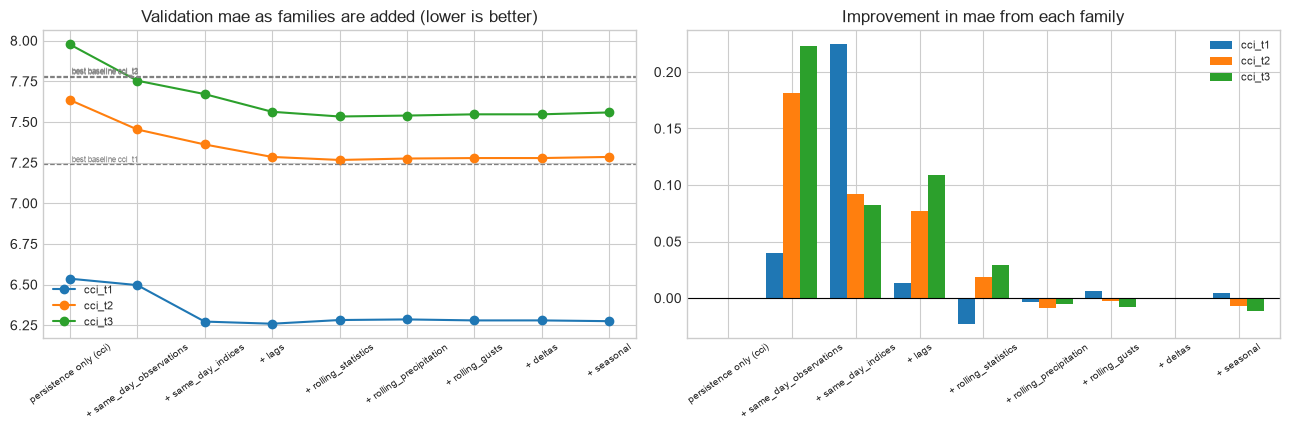

target,cci_t1,cci_t2,cci_t3,n_features
config,,,,
persistence only (cci),6.536,7.635,7.977,1
+ same_day_observations,6.496,7.454,7.754,6
+ same_day_indices,6.272,7.361,7.671,17
+ lags,6.259,7.285,7.562,49
+ rolling_statistics,6.282,7.266,7.533,89
+ rolling_precipitation,6.285,7.275,7.539,93
+ rolling_gusts,6.279,7.278,7.547,97
+ deltas,6.279,7.278,7.547,103
+ seasonal,6.275,7.285,7.558,105


In [29]:
ablation = exp.run_ablation()
plt.show()
ablation

---
## 5. Hyperparameter tuning

Optuna (seeded TPE sampler) searches the space defined in section 1, **on all
features**. Every trial is cross-validated on the four folds and scored by its
mean, so the search cannot overfit to one year. Each target is tuned separately.
The plots show the search history and which settings mattered most.

In [30]:
exp.tune(n_trials=N_TRIALS)

[cci_polynomial_regression] tuning cci_t1: 20 trials x 4 folds


[I 2026-09-19 17:59:27,761] A new study created in memory with name: cci_polynomial_regression_cci_t1
[I 2026-09-19 17:59:53,860] Trial 0 finished with value: 12.496806877631013 and parameters: {'degree': 2, 'interaction_only': False, 'alpha': 0.4356821271417881}. Best is trial 0 with value: 12.496806877631013.
[I 2026-09-19 17:59:54,212] Trial 1 finished with value: 6.311265171663781 and parameters: {'degree': 1, 'interaction_only': False, 'alpha': 3873.9746708167268}. Best is trial 1 with value: 6.311265171663781.
[I 2026-09-19 18:00:17,777] Trial 2 finished with value: 8.7424633160262 and parameters: {'degree': 2, 'interaction_only': True, 'alpha': 26.65811983933415}. Best is trial 1 with value: 6.311265171663781.
[I 2026-09-19 18:00:17,944] Trial 3 finished with value: 6.266898045899274 and parameters: {'degree': 1, 'interaction_only': False, 'alpha': 103.13141058928771}. Best is trial 3 with value: 6.266898045899274.
[I 2026-09-19 18:00:18,125] Trial 4 finished with value: 6.27701

[cci_polynomial_regression] best cci_t1: mean mae = 6.2654 (225s)
[cci_polynomial_regression] tuning cci_t2: 20 trials x 4 folds


[I 2026-09-19 18:03:12,814] A new study created in memory with name: cci_polynomial_regression_cci_t2
[I 2026-09-19 18:03:38,627] Trial 0 finished with value: 13.703004601601407 and parameters: {'degree': 2, 'interaction_only': False, 'alpha': 0.4356821271417881}. Best is trial 0 with value: 13.703004601601407.
[I 2026-09-19 18:03:38,806] Trial 1 finished with value: 7.2822558815502765 and parameters: {'degree': 1, 'interaction_only': False, 'alpha': 3873.9746708167268}. Best is trial 1 with value: 7.2822558815502765.
[I 2026-09-19 18:04:02,565] Trial 2 finished with value: 10.227942513748957 and parameters: {'degree': 2, 'interaction_only': True, 'alpha': 26.65811983933415}. Best is trial 1 with value: 7.2822558815502765.
[I 2026-09-19 18:04:02,737] Trial 3 finished with value: 7.276316445141913 and parameters: {'degree': 1, 'interaction_only': False, 'alpha': 103.13141058928771}. Best is trial 3 with value: 7.276316445141913.
[I 2026-09-19 18:04:02,883] Trial 4 finished with value: 7

[cci_polynomial_regression] best cci_t2: mean mae = 7.2750 (167s)
[cci_polynomial_regression] tuning cci_t3: 20 trials x 4 folds


[I 2026-09-19 18:05:59,943] A new study created in memory with name: cci_polynomial_regression_cci_t3
[I 2026-09-19 18:06:23,742] Trial 0 finished with value: 14.311344300872484 and parameters: {'degree': 2, 'interaction_only': False, 'alpha': 0.4356821271417881}. Best is trial 0 with value: 14.311344300872484.
[I 2026-09-19 18:06:23,960] Trial 1 finished with value: 7.533922318171392 and parameters: {'degree': 1, 'interaction_only': False, 'alpha': 3873.9746708167268}. Best is trial 1 with value: 7.533922318171392.
[I 2026-09-19 18:06:47,036] Trial 2 finished with value: 10.685273460890413 and parameters: {'degree': 2, 'interaction_only': True, 'alpha': 26.65811983933415}. Best is trial 1 with value: 7.533922318171392.
[I 2026-09-19 18:06:47,237] Trial 3 finished with value: 7.546016361677912 and parameters: {'degree': 1, 'interaction_only': False, 'alpha': 103.13141058928771}. Best is trial 1 with value: 7.533922318171392.
[I 2026-09-19 18:06:47,410] Trial 4 finished with value: 7.56

[cci_polynomial_regression] best cci_t3: mean mae = 7.5339 (196s)


,cv_mae,trials,best_params
target,,,
cci_t1,6.265,20,"{'degree': 1, 'interaction_only': True, 'alpha..."
cci_t2,7.275,20,"{'degree': 1, 'interaction_only': True, 'alpha..."
cci_t3,7.534,20,"{'degree': 1, 'interaction_only': False, 'alph..."


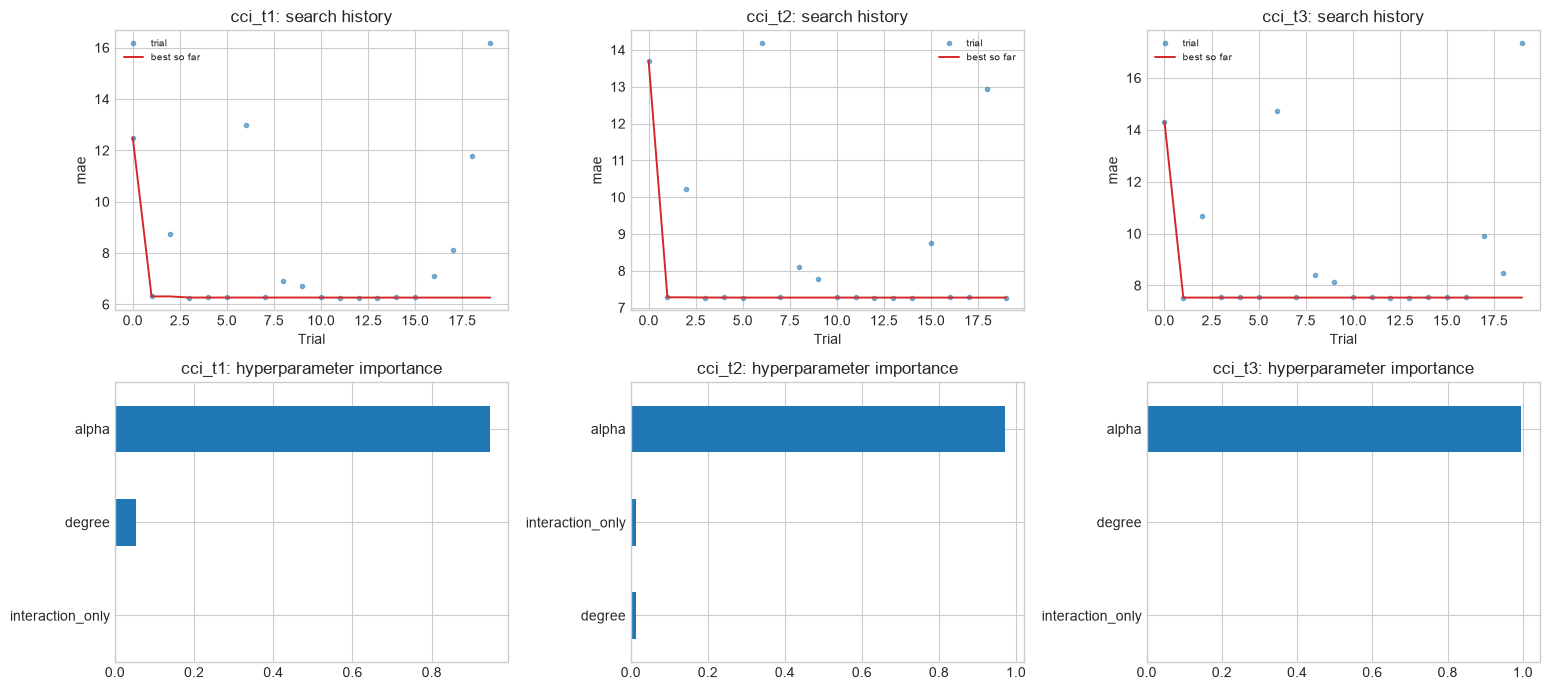

In [31]:
exp.plot_search()
plt.show()

---
## 6. Cross-validated results

The chosen configuration is cross-validated again and compared with the untuned `default` and every baseline, all on the same folds. `gain_of_model` is positive when the model beats that row. The plot shows the **out-of-fold predictions**: every validation year predicted by a model that never saw it.

`pred_std` is shown next to the error metrics. A spread far below the observed spread means the
model is playing safe by predicting close to the average, which can give a respectable MAE while
missing exactly the uncomfortable days users care about. Expect error to grow with the horizon.

In [32]:
exp.assess()

[cci_polynomial_regression] assess cci_t1: tuned mean mae = 6.2654 (best baseline 7.2395)
[cci_polynomial_regression] assess cci_t2: tuned mean mae = 7.2750 (best baseline 7.7842)
[cci_polynomial_regression] assess cci_t3: tuned mean mae = 7.5339 (best baseline 7.7788)


mae   rmse     r2  pred_std  train_mae  gain_of_model
target model                                                               
cci_t1 climatology  7.789 10.406  0.002     3.712        NaN          1.523
       default      9.425 13.501 -0.728    11.540      4.420          3.159
       persistence  7.240  9.614  0.142    10.407        NaN          0.974
       tuned        6.265  8.360  0.353     6.383      5.833         -0.000
cci_t2 climatology  7.784 10.401  0.003     3.700        NaN          0.509
       default     10.967 14.949 -1.086    11.686      4.988          3.692
       persistence  9.069 11.788 -0.295    10.407        NaN          1.795
       tuned        7.275  9.562  0.152     4.633      6.737         -0.000
cci_t3 climatology  7.779 10.398  0.004     3.701        NaN          0.245
       default     11.494 16.134 -1.487    13.297      5.115          3.960
       persistence  9.917 12.783 -0.529    10.407        NaN          2.383
       tuned        7.534  9.928  0.088     3.892      6.976         -0.000

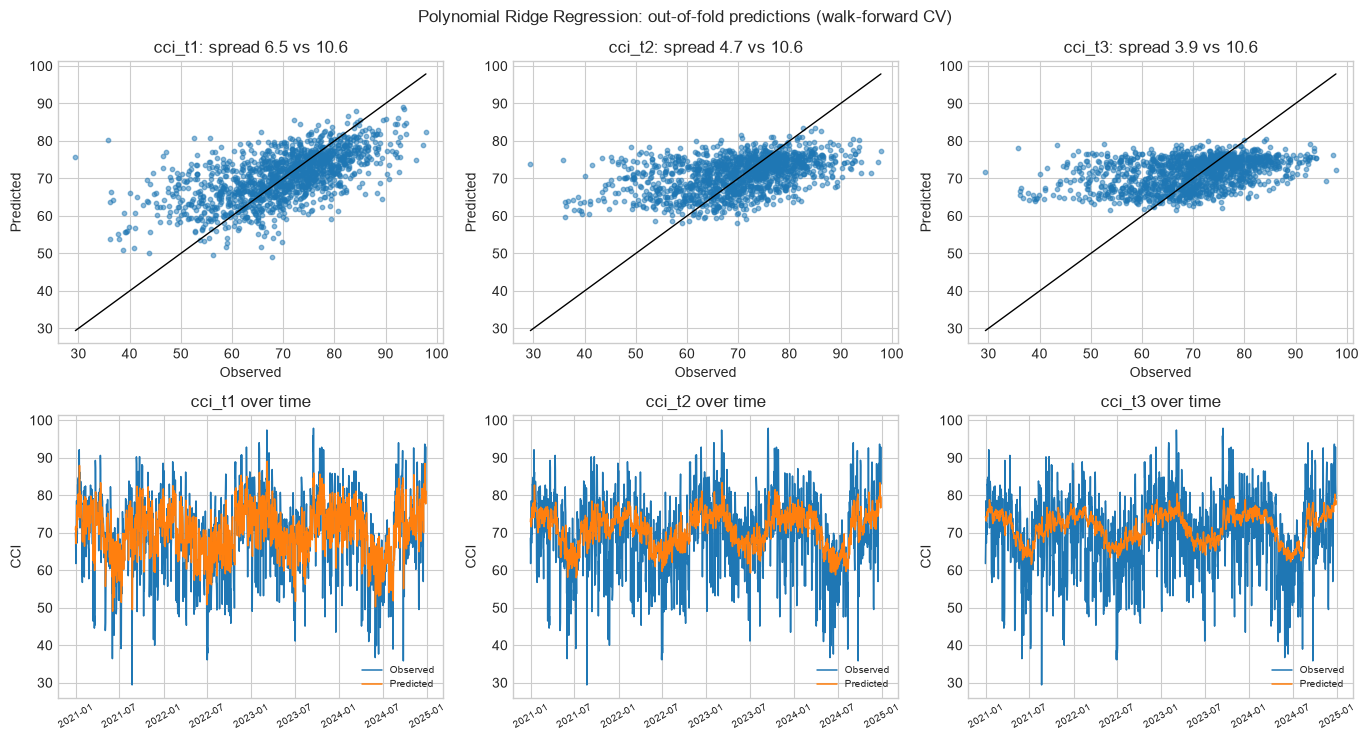

In [33]:
exp.plot_validation()
plt.show()

---
## 7. Feature importance

This model has no built-in importance, so **permutation importance** is used: each feature is shuffled on the validation split and the drop in score is recorded. Features with negative importance are candidates for pruning.

> Importance is measured on the last fold's model and validation year (2024). Correlated features share importance, so the ablation in section 4 is the better guide to what can be removed.

[cci_polynomial_regression] computing feature importance (permutation importance can take a while)


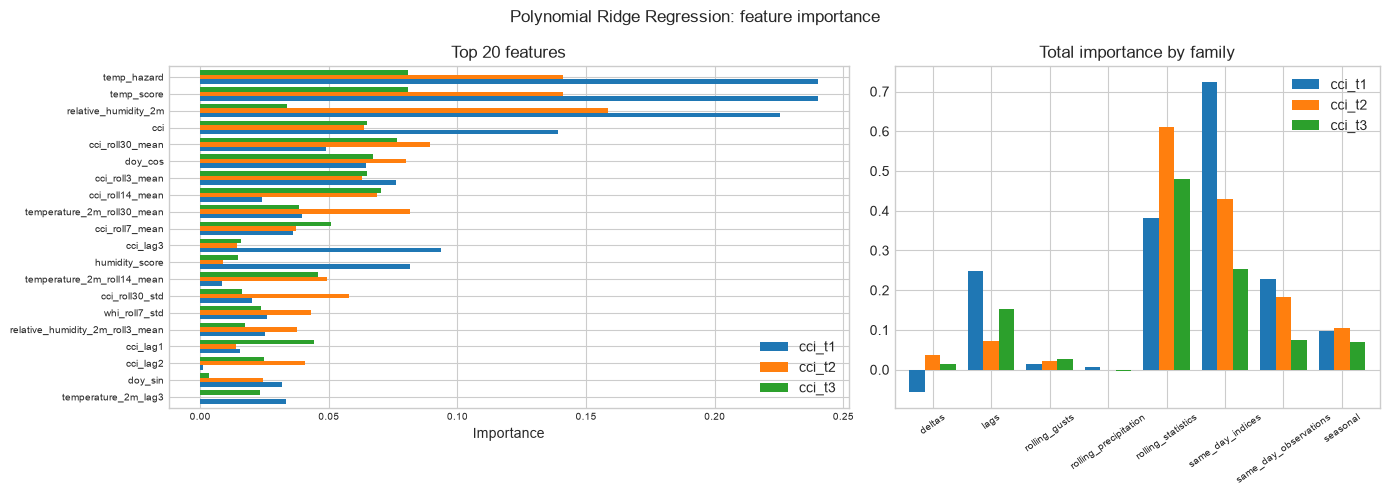

,cci_t1,cci_t2,cci_t3
deltas,-0.057,0.037,0.014
lags,0.249,0.073,0.152
rolling_gusts,0.014,0.021,0.028
rolling_precipitation,0.008,-0.001,-0.002
rolling_statistics,0.382,0.610,0.480
same_day_indices,0.725,0.429,0.253
same_day_observations,0.228,0.184,0.075
seasonal,0.096,0.104,0.071


In [34]:
family_importance = exp.importance()
plt.show()
family_importance

---
## 8. Generalisation check

Mean training and validation scores over the folds. A small gap means the model
generalises; a large gap means it memorises the training years.

In [35]:
exp.generalisation()

,train_mae,validation_mae,validation_minus_train
target,,,
cci_t1,5.833,6.265,0.432
cci_t2,6.737,7.275,0.538
cci_t3,6.976,7.534,0.558


---
## 9. Save the experiment bundle

The chosen configuration is refitted on **all development data** and saved to
`models/comfort_climate/experiments/cci_polynomial_regression/`:

| File | Contents |
|:--|:--|
| `cci_polynomial_regression_h<horizon>.joblib` | The model, one per horizon |
| `metadata.json` | Settings, features, importance and the cross-validated scores |
| `manifest.json` | File list and the feature column order |
| `spec.joblib` | The specification and tuned settings, which the comparison notebook uses to rebuild this experiment |

In [36]:
exp.export()

[cci_polynomial_regression] final fit cci_t1: 9,099 rows, 105 features
[cci_polynomial_regression] final fit cci_t2: 9,099 rows, 105 features
[cci_polynomial_regression] final fit cci_t3: 9,099 rows, 105 features
Saved bundle: models/comfort_climate/experiments/cci_polynomial_regression


PosixPath('/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/models/comfort_climate/experiments/cci_polynomial_regression')

---
## 10. Conclusions

- **Against the baselines.** Does the tuned model beat both persistence and climatology at
  every horizon (section 6), and how much did tuning add over the default?
- **What the ablation says about a linear model.** If adding families makes the score worse, the
  penalty is too weak for the wide, collinear matrix; check which `alpha` the search chose, and
  expect feature selection in the comparison notebook to help this model most.

> If this algorithm is shortlisted, the comparison notebook selects its feature families with walk-forward cross-validation and briefly re-tunes its settings on the chosen features.

> The test split has still not been used. It is scored exactly once, in the `cci_comparison` notebook, after the champion has been chosen.